# Direct component API

This tutorial uses importable Python objects. Constructors validate settings; `build()` initializes shared resources and creates an independent executable graph. No registration decorators are needed.

Three structures have distinct roles: the immutable **declaration graph**, its prepared **execution graph** with the same placement IDs, and **candidate lineage** produced during a run. A node ID identifies a graph placement; a position such as `0.steps.1` is a readable address that may change after insertion. Candidate IDs identify peptides within a run.

Run from an environment installed with the CPU or an appropriate CUDA extra. The examples use CPU, seed 7, the bundled HydrAMP weights and a short APEX demonstration. No model training is performed.

In [16]:
from pathlib import Path
from tempfile import TemporaryDirectory
from IPython.display import display

from pep_compass import Pipeline, PipelineBuilder
from pep_compass.autoencoder import HydrAMP
import pep_compass.steps as st
from pep_compass.steps.filters import CandidateSubset, Deduplicate
from pep_compass.steps.flow import LocalEnumeration, Loop
from pep_compass.steps.mutations import Mutang
from pep_compass.steps.oracles import Hydrophobicity
from pep_compass.steps.saving import Snapshot
from pep_compass.steps.walkers import Sorbes

pipeline = Pipeline()
pipeline.describe()  # USAGE: automatic formatted display; weights are not loaded.

component,strategy,description,internal_stages
filters,Deduplicate,Keep the first candidate for every configured identity key.,
filters,CandidateSubset,Select at most a fixed number of candidates from the complete batch.,
filters,Levenshtein,Keep sequences within an inclusive edit radius of a reference.,
filters,SequenceLength,Keep sequences whose lengths lie in an inclusive interval.,
filters,TrustRegion,Retain candidates within the current objective-specific trust region.,
filters,TrustRegionUpdate,Update center and radius from scores already attached by an oracle.,
filters,Robot,Select a diverse batch using GP expected improvement. The selector reads observations collected by an oracle from,
filters,RandomMutationPool,Apply random proposals or random ranking to each MUTANG parent pool.,
filters,Ranked,Compose one score function with one score-based selection rule.,"scoring, selection"
filters,Lams,Compose LAMS scoring and threshold selection without a marker subclass.,


In [2]:
pipeline.describe("filters", display="pd")  # USAGE: return a reusable pandas DataFrame.
pipeline.describe_component(CandidateSubset)  # Required values, constructor defaults and help.
pipeline.describe_component(Sorbes(), technical=True)  # Resolved internal stages and field contract.
raw = pipeline.describe_component(CandidateSubset(count=3), display="raw")
assert raw["configuration"]["count"] == 3

## Constructing and editing pipelines

A component is an actual object imported from its category. Internal strategy implementations live under `strategies/`; `__init__.py` exports the public objects. All three construction styles below produce the same computation. `add_component()` and builder `add()` return stable IDs. `build()` returns an `ExecutablePipeline`, while the wrapper keeps its editable builder.

`show()` embeds an SVG picture. `to_schema("mermaid")` returns editable diagram source; Mermaid needs a compatible renderer to display it. `text` is a readable listing, `json` is a portable declaration, and `object` is the immutable `PipelineSchema`. None of these views executes the graph.

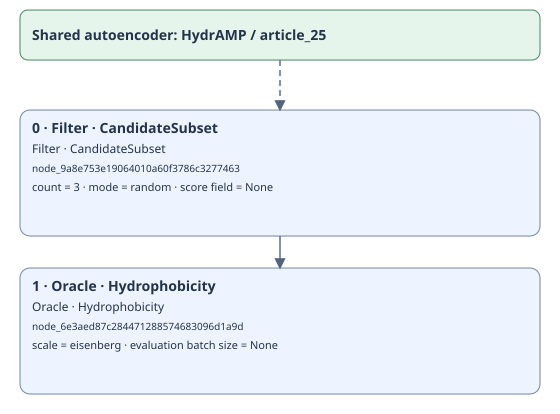

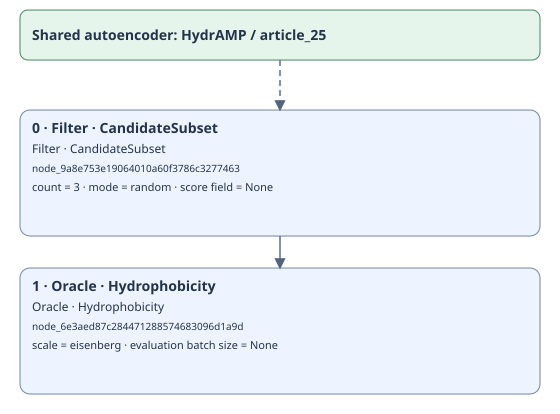

In [ ]:
# USAGE: 1. Add concrete components incrementally.
incremental = Pipeline(autoencoder=HydrAMP(jacobian_mode="approx"))
selection_id = incremental.add_component(st.filters.CandidateSubset(count=3))
incremental.add_component(Hydrophobicity())
display(incremental.show())
compiled_incremental = incremental.build()
display(compiled_incremental.show())
assert incremental.to_schema().steps[0].node_id == selection_id

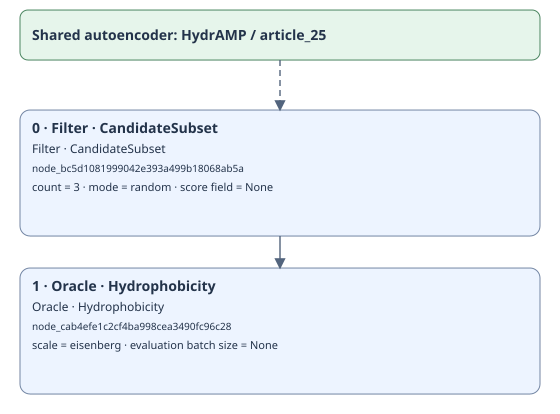

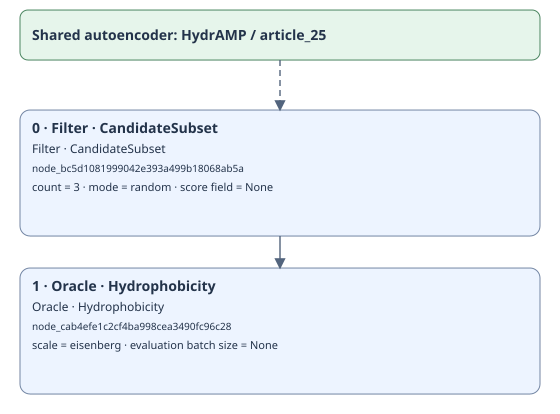

In [4]:
# USAGE: 2. Pass the complete ordered component list.
constructed = Pipeline(
    [CandidateSubset(count=3), Hydrophobicity()],
    autoencoder=HydrAMP(jacobian_mode="approx"),
)
display(constructed.show())
compiled_constructed = constructed.build()
display(compiled_constructed.show())

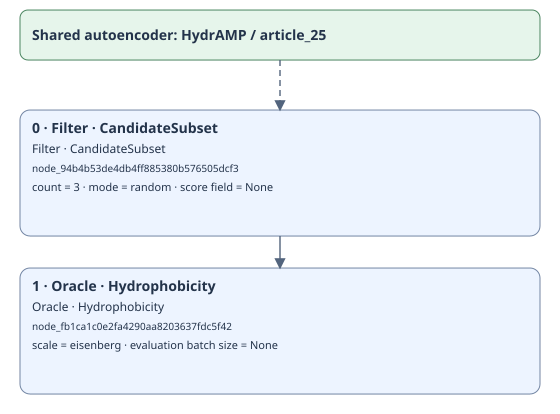

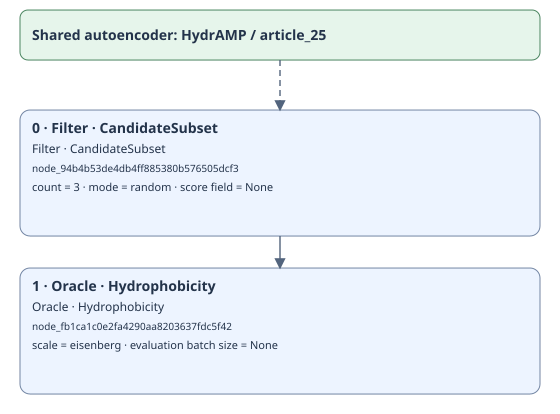

In [5]:
# USAGE: 3. Collect components with a standalone builder.
builder = PipelineBuilder(autoencoder=HydrAMP(jacobian_mode="approx"))
builder.add(CandidateSubset(count=3))
builder.add(Hydrophobicity())
from_builder = Pipeline.from_schema(builder.schema)
display(from_builder.show())
compiled_from_builder = builder.build()
display(compiled_from_builder.show())
assert [node.to_config() for node in builder.schema.steps] == [node.to_config() for node in constructed.to_schema().steps]

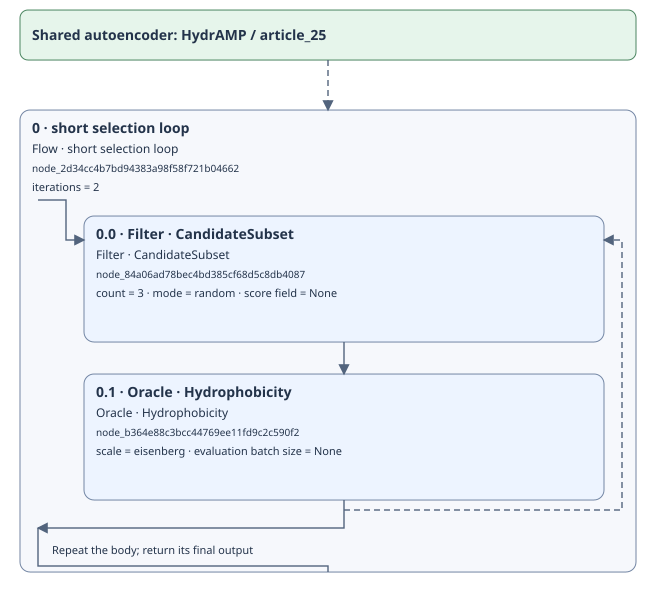

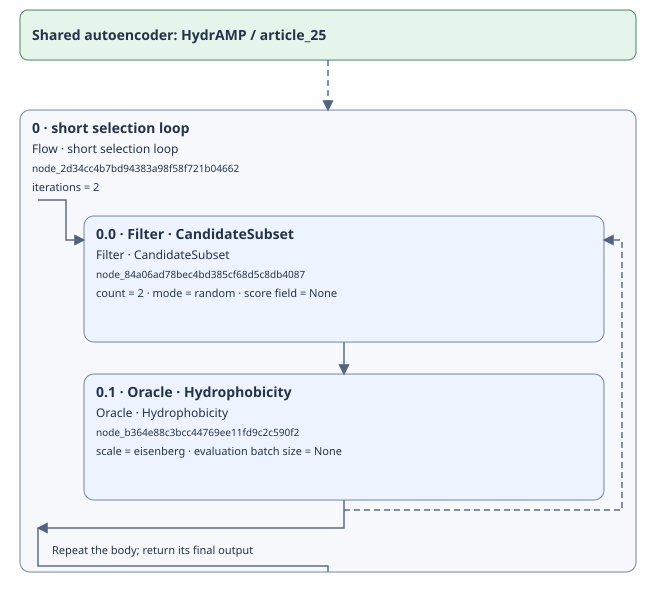

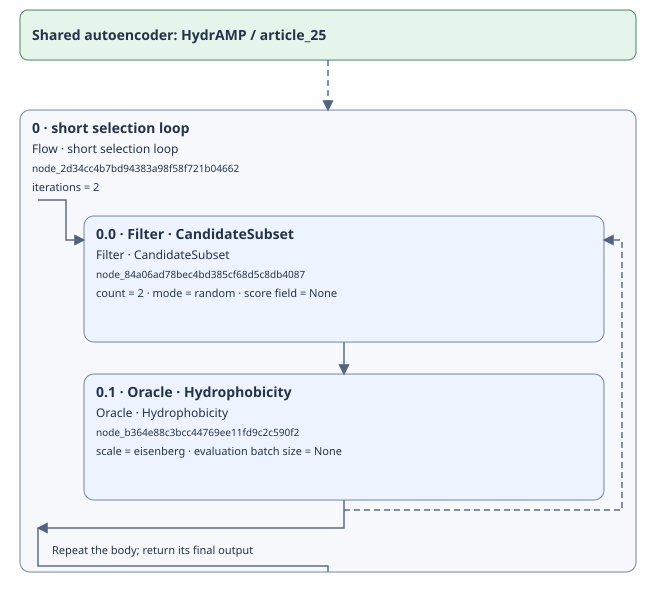

In [6]:
# USAGE: Insert, replace and remove by stable ID before rebuilding.
editable = Pipeline(autoencoder=HydrAMP(jacobian_mode="approx"))
with editable.loop(iterations=2, name="short selection loop") as body:
    stable_id = body.add(CandidateSubset(count=3))
    body.add(Hydrophobicity())
display(editable.show())
inserted_id = editable.insert_component(Deduplicate(), before=stable_id)
editable.replace_component(stable_id, CandidateSubset(count=2))
editable.describe_component(node_id=stable_id)
editable.remove_component(inserted_id)
display(editable.show())
compiled_editable = editable.build()
display(compiled_editable.show())

## Runner defaults and per-run overrides

Graph structure determines iteration counts. Runner settings control execution, retained information and the return view. They do not add or remove steps. Per-run overrides leave the configured defaults unchanged. Every run creates fresh optimization state; seed scopes restore the caller's Python, NumPy and Torch RNG state.

The next three cells set every supported runner option explicitly, with the default stated beside it. Oracle and generation limits are checked at complete-batch boundaries: a completed evaluation batch is retained even when it crosses a threshold.

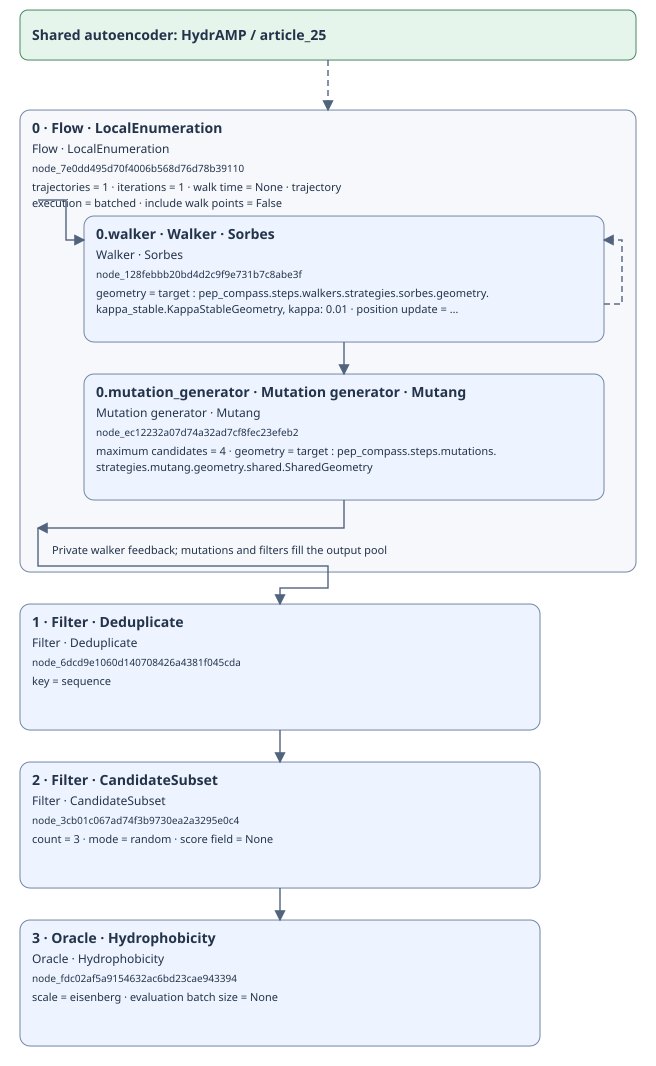

In [7]:
pipeline = Pipeline(
    [
        LocalEnumeration(
            walker=Sorbes(), mutation_generator=Mutang(maximum_candidates=4),
            trajectories=1, iterations=1, include_walk_points=False,
        ),
        Deduplicate(), CandidateSubset(count=3), Hydrophobicity(),
    ],
    autoencoder=HydrAMP(jacobian_mode="approx"),
)
pipeline.set_runner_settings(execution={
    "seed": 7,  # USAGE: deterministic run seed; default None.
    "device": "cpu",  # USAGE: resource device; default None uses the resource declaration.
    "oracle_calls": 3,  # REMARK: complete-batch threshold; default None is unbounded.
    "generated_candidates": None,  # Default None; local allocation caps belong to Mutang.
    "max_workers": 1,  # Default and supported value 1; independent jobs use the orchestrator.
})
compiled = pipeline.build()
display(compiled.show())

In [8]:
pipeline.set_runner_settings(storage={
    "backend": "memory",  # Default memory; sqlite writes a persistent run directory.
    "path": None,  # Default None; required directory for sqlite.
    "profile": "base",  # Default base: evaluated sequences and compact statistics.
    "flush_every": 1,  # Default 1: commit after each iteration, without sampling rows.
    "reconstruction": "none",  # Default none; boundaries adds replay, trajectories adds walk points.
    "component_data": "none",  # Default none; summary or full retain component diagnostics.
    "save_observation_history": False,  # Default False; True retains repeated evaluations.
    "save_lineage": False,  # Default False; True retains evaluated archive parent IDs.
    "save_terminal": False,  # Default False; True retains the separate outgoing batch.
})
# REMARK: Add Snapshot("label") at a graph position to retain an explicit batch.
pipeline.set_runner_settings(results={
    "return_mode": "result",  # Default result; alternatives reader and path (SQLite only).
})

In [9]:
inputs = ["FLYKWWIRIGRLKL"]
base_result = pipeline.run(inputs)
display(base_result.reader.get_archive())
display(base_result.summary)
assert base_result.summary["oracle_calls"] == 3

,objective,sequence,score,direction,evaluation_index,first_evaluation_index,lineage_json
0,hydrophobicity,FLYKWWIRIGRLWL,0.283571,maximize,0,0,{}
1,hydrophobicity,FLYKWWPRIGRLKL,0.027143,maximize,1,1,{}
2,hydrophobicity,FLYKWWPRIGRLWL,0.192143,maximize,2,2,{}


{'status': 'completed',
 'duration_seconds': 2.7163561950001167,
 'oracle_calls': 3,
 'generated_candidates': 4,
 'completed_iterations': 1,
 'iteration_events': 1,
 'best_sequence': 'FLYKWWIRIGRLWL',
 'best_score': 0.28357142857142853,
 'objective_name': 'hydrophobicity',
 'terminal_count': 3,
 'error': None}

In [10]:
# USAGE: Retain replay boundaries and walker trajectories for this run only.
retained_result = pipeline.run(inputs, storage={
    "reconstruction": "trajectories", "component_data": "summary",
    "save_observation_history": True, "save_lineage": True, "save_terminal": True,
})
display(retained_result.reader.get_history())
display(retained_result.reader.get_component_data())
checkpoint = int(retained_result.reader.get_checkpoints().iloc[0]["checkpoint_id"])
assert retained_result.reader.reconstruct_local_enumeration(checkpoint).matches
points, latent_positions = retained_result.reader.get_trajectories()
display(points)
assert len(points) == len(latent_positions)

,observation_id,objective,sequence,score,direction,lineage_json
0,1,hydrophobicity,FLYKWWIRIGRLWL,0.283571,maximize,"{""lineage.candidate_id"": 3, ""lineage.parent_ca..."
1,2,hydrophobicity,FLYKWWPRIGRLKL,0.027143,maximize,"{""lineage.candidate_id"": 4, ""lineage.parent_ca..."
2,3,hydrophobicity,FLYKWWPRIGRLWL,0.192143,maximize,"{""lineage.candidate_id"": 5, ""lineage.parent_ca..."


,record_id,node_id,execution_id,name,payload_id,data
0,1,node_128febbb20bd4d2c9f9e731b7c8abe3f,6,Sorbes,4148b708c682ca41f3d9722911b519949d114adc9d2818...,{'geometry': {'_target_': 'pep_compass.steps.w...
1,2,node_ec12232a07d74a32ad7cf8fec23efeb2,7,Mutang,0acce1925ae47f42557e8b95729ea45ae251e8ed7a8d6b...,"{'maximum_candidates': 4, 'geometry': {'_targe..."
2,3,node_7e0dd495d70f4006b568d76d78b39110,8,Flow,748f9502391386d7c90056bd76194f86f237ea8dc88633...,{}
3,4,node_7e0dd495d70f4006b568d76d78b39110,5,LocalEnumeration,fec2659a4f24309efc2cfe51aaf99f3f0d54583462fb2b...,"{'trajectories': 1, 'iterations': 1, 'walk_tim..."
4,5,node_6dcd9e1060d140708426a4381f045cda,9,Deduplicate,714d6f4feb5c4a885c5698b5d7c9212f2bc512ff987872...,{'key': 'sequence'}
5,6,node_3cb01c067ad74f3b9730ea2a3295e0c4,10,CandidateSubset,b475e97980e05055eceda2b8384731da31ebcfbfa90b4f...,"{'count': 3, 'mode': 'random', 'score_field': ..."
6,7,node_fdc02af5a9154632ac6bd23cae943394,11,Hydrophobicity,f1c09745416001ca731b8e3a7376af24a95a50bbfe391f...,"{'scale': 'eisenberg', 'evaluation_batch_size'..."
7,8,None,4,Flow,748f9502391386d7c90056bd76194f86f237ea8dc88633...,{}


,execution_id,sequence,latent_index,trajectory_id,trajectory_index,trajectory_step,candidate_id
0,6,FLYKWWIRIGRLKL,0,Flow/LocalEnumeration/branch[batched_trajector...,0,0,1


In [11]:
# USAGE: Exercise persistent output and the same lazy reader contract.
artifacts = TemporaryDirectory(prefix="pep-compass-tutorial-")
run_path = Path(artifacts.name) / "sqlite-run"
disk_result = pipeline.run(inputs, storage={
    "backend": "sqlite", "path": str(run_path), "save_terminal": True,
})
display(disk_result.reader.get_archive())
assert (run_path / "settings.json").is_file()
assert (run_path / "results.sqlite").is_file()
assert len(disk_result.reader.get_final_batch()) == disk_result.summary["terminal_count"]

,objective,sequence,score,direction,evaluation_index,first_evaluation_index,lineage_json
0,hydrophobicity,FLYKWWIRIGRLWL,0.283571,maximize,0,0,{}
1,hydrophobicity,FLYKWWPRIGRLKL,0.027143,maximize,1,1,{}
2,hydrophobicity,FLYKWWPRIGRLWL,0.192143,maximize,2,2,{}


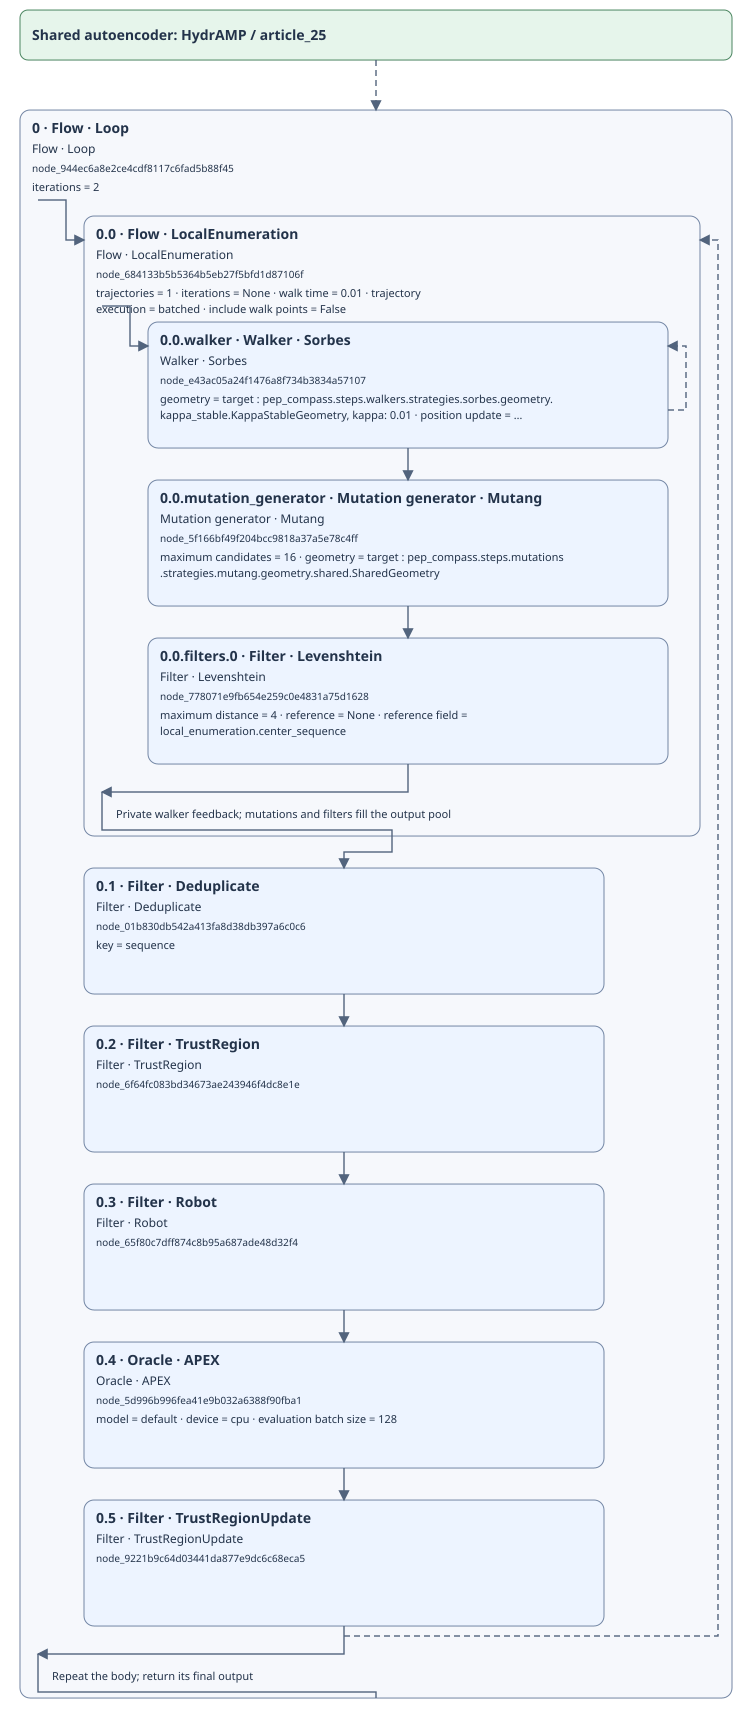

,objective,sequence,score,direction,evaluation_index,first_evaluation_index,lineage_json
0,apex,FLYWWWFRIGRLWL,5.246353,minimize,0,0,{}
1,apex,FLYWWWIRIGRLWL,4.640906,minimize,1,1,{}
2,apex,FLYWWWIRPGRLWL,5.850920,minimize,2,2,{}


In [12]:
# USAGE: A bounded LE-BO preset uses the same public component objects.
from pep_compass.predefined import lebo

bayesian = lebo(
    device="cpu", seed=7, mutation_candidates=16, oracle_calls=3,
    iterations=2, trajectories=1, walk_time=0.01,
)
display(bayesian.show())
bayesian_result = bayesian.run(inputs)
display(bayesian_result.reader.get_archive())
assert bayesian_result.summary["oracle_calls"] >= 1

## Persistence and analysis

`results.sqlite` contains the common logical tables and typed tensor payloads; `settings.json` records the resolved graph, inputs, runner settings and model provenance. Memory storage uses the same relational schema. `RunResult.save()` exports retained information without re-running a computation. CSV is an optional table export; it cannot preserve tensor payloads or replay state.

The evaluated archive and outgoing terminal batch are distinct. `base` keeps evaluated peptides, including those removed by later selection. Terminal tensors, repeated observations, lineage, component data and reconstruction are opt-in. Replay is explicit and verifies the saved sequence digest against the retained boundary.

`AnalysisReader` accesses one run lazily. `ExperimentReader` discovers a collection and uses the same table contract for selection and analysis, so writers and analyses agree on field meanings. Table handles support bounded projected scans. Locality analyses need trajectory retention and the relevant candidate batch.

In [13]:
from pep_compass.optimization.saving import AnalysisReader
from pep_compass.analysis.reader import ExperimentReader

exported_path = base_result.save(Path(artifacts.name) / "exported-memory")
with AnalysisReader(exported_path) as reader:
    display(reader.get_archive())
    display(reader.get_metadata()["summary"])
    for chunk in reader.tables["evaluated_peptides"].scan(["sequence", "score"], chunk_size=2):
        display(chunk)

collection = ExperimentReader(artifacts.name)
display(collection.select(seeds=[7]).collect("evaluated_peptides", columns=["sequence", "score", "seed"]))
base_result.reader.get_archive().to_csv(Path(artifacts.name) / "evaluated.csv", index=False)
pipeline.save_schema(Path(artifacts.name) / "pipeline.json")

,objective,sequence,score,direction,evaluation_index,first_evaluation_index,lineage_json
0,hydrophobicity,FLYKWWIRIGRLWL,0.283571,maximize,0,0,{}
1,hydrophobicity,FLYKWWPRIGRLKL,0.027143,maximize,1,1,{}
2,hydrophobicity,FLYKWWPRIGRLWL,0.192143,maximize,2,2,{}


{'status': 'completed',
 'duration_seconds': 2.7163561950001167,
 'oracle_calls': 3,
 'generated_candidates': 4,
 'completed_iterations': 1,
 'iteration_events': 1,
 'best_sequence': 'FLYKWWIRIGRLWL',
 'best_score': 0.28357142857142853,
 'objective_name': 'hydrophobicity',
 'terminal_count': 3,
 'error': None}

,sequence,score
0,FLYKWWIRIGRLWL,0.283571
1,FLYKWWPRIGRLKL,0.027143


,sequence,score
0,FLYKWWPRIGRLWL,0.192143


,sequence,score,seed
0,FLYKWWIRIGRLWL,0.283571,7
1,FLYKWWPRIGRLKL,0.027143,7
2,FLYKWWPRIGRLWL,0.192143,7
3,FLYKWWIRIGRLWL,0.283571,7
4,FLYKWWPRIGRLKL,0.027143,7
5,FLYKWWPRIGRLWL,0.192143,7


PosixPath('/tmp/pep-compass-tutorial-c9bynbir/pipeline.json')

## The same constructors in Hydra

A YAML `_target_` imports the same class or preset function used above. YAML defaults select configuration groups; overrides replace parameters or entire groups. The orchestrator plans independent jobs and passes each frozen graph to the Python wrapper. Local, subprocess and server-owned Slurm templates are execution strategies configured by their own `_target_`.

Example CLI: `pep-compass plan pipeline=simple pipeline.mutation_candidates=8 backend=slurm +backend.settings.time=00:05:00`. Planning validates declarations without loading weights.

In [14]:
from pep_compass.orchestrator.configuration import compose_configuration
from pep_compass.orchestrator.planning import plan_configuration

configuration = compose_configuration(["pipeline=simple", "pipeline.mutation_candidates=8"])
plan = plan_configuration(configuration)
assert plan.schema.steps[0].children["mutation_generator"].parameters["maximum_candidates"] == 8
print("Planned independent jobs:", len(plan.entries))
# REMARK: Orchestrator().run(plan) dispatches the jobs; this cell only plans.

Planned independent jobs: 1


In [15]:
# USAGE: Close results before cleaning up temporary output directories.
for result in (base_result, retained_result, disk_result, bayesian_result):
    result.close()
artifacts.cleanup()